# EDA รอบ 2 — กระเป๋าที่ถูกติดธง vs ไม่ถูกติดธง (บทบาท C)

รอบ 1 ดูข้อมูลดิบสองสัปดาห์ รอบนี้ใช้ **ผลของ Algorithm 1** (ธงรายกระเป๋าจาก `07_wallet_flags.py`)
มาตอบคำถามเดียว: **กระเป๋าที่อัลกอริทึมติดธง (score ≥ θ) ต่างจากกระเป๋าทั่วไปอย่างไร** และต่างไป
ในทางที่สอดคล้องกับ "wash trading" หรือไม่ (วนเทรดกับคู่เดิม, ตลาด long-shot ราคาต่ำ, จับกลุ่มกันเอง)

> ⚠️ ต้องรัน `04_Evaluation/premise_test/07_wallet_flags.py` ก่อน เพื่อสร้าง
> `results/wallet_flags/<window>.parquet` — notebook นี้อ่านไฟล์นั้น

## 0. ตั้งค่า

In [1]:
import json
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Project/ = two levels up from this notebook (03_Analytics/eda/)
PROJECT = Path.cwd().resolve()
while not (PROJECT / "pyproject.toml").exists():
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT / "04_Evaluation" / "premise_test"))
from config import INTERIM, RAW, RESULTS, THETA, WINDOWS  # noqa: E402

HERE = PROJECT / "03_Analytics" / "eda"
FIG = HERE / "figures"
FIG.mkdir(parents=True, exist_ok=True)
WFLAGS = RESULTS / "wallet_flags"
ALG1_JSON = RESULTS / "alg1_results.json"
MARKETS = str(RAW / "market_data.parquet")

con = duckdb.connect()
con.execute("SET TimeZone = 'UTC'")  # match the premise test's UTC weeks


def q(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()


def trades(w: str) -> str:
    return str(INTERIM / f"{w}_trades.parquet")


def flags(w: str) -> str:
    return str(WFLAGS / f"{w}.parquet")


pd.set_option("display.max_colwidth", 70)
print("theta =", THETA, "| windows:", list(WINDOWS))

theta = 0.9 | windows: ['dec2024', 'jun2025']


In [2]:
# Same hues as round 1 / the plan PDF. Flagged = orange (the algorithm's call), unflagged = blue.
C_DATA, C_ALG, C_EVAL, C_MUTED, C_INK = "#0072B2", "#D55E00", "#009E73", "#5B6B7A", "#1A2733"
GRP = {"flagged": C_ALG, "unflagged": C_DATA}
WIN = {
    "dec2024": {"label": "Dec 2024 (peak)", "color": C_DATA},
    "jun2025": {"label": "Jun 2025 (quiet)", "color": C_EVAL},
}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK, "text.color": C_INK,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})
STATS: dict = {w: {} for w in WIN}


def save_fig(fig, name: str) -> None:
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")


def record_stat(w: str, key: str, value) -> None:
    value = value.item() if hasattr(value, "item") else value
    if isinstance(value, float) and value.is_integer():
        value = int(value)
    STATS[w][key] = value

## 1. โหลดธงรายกระเป๋า + ตรวจความถูกต้อง

หนึ่งแถว = หนึ่งกระเป๋า มีคอลัมน์หลัก `x` (score), `flagged` (x ≥ θ), `target_vol`,
`target_wash_vol`, `in_wash_trade`, `n_markets`, `n_counterparties`
ตัวเลขจำนวนกระเป๋า/กระเป๋าที่ถูกติดธง/สัดส่วน volume ต้องตรงกับ `wallet_flags/summary.json`
และสัดส่วน wash volume ต้องตรงกับ premise test (`alg1_results.json`)

In [3]:
fl = {w: q(f"SELECT * FROM '{flags(w)}'") for w in WIN}
summ = {s["window"]: s for s in json.loads((WFLAGS / "summary.json").read_text())}

rows = []
for w in WIN:
    d, s = fl[w], summ[w]
    assert len(d) == s["wallets"], (w, len(d), s["wallets"])
    assert int(d["flagged"].sum()) == s["flagged_wallets"], w
    rows.append({
        "window": WIN[w]["label"],
        "wallets": len(d),
        "flagged": int(d["flagged"].sum()),
        "flagged %": round(100 * d["flagged"].mean(), 2),
        "wash % of target vol": round(100 * s["wash_volume_share"], 2),
    })
    record_stat(w, "n_wallets", len(d))
    record_stat(w, "n_flagged", int(d["flagged"].sum()))
    record_stat(w, "pct_wallets_flagged", 100 * d["flagged"].mean())
    record_stat(w, "pct_target_volume_wash", 100 * s["wash_volume_share"])

# Cross-check the wash fraction against the premise test, if that file is present.
if ALG1_JSON.exists():
    alg = json.loads(ALG1_JSON.read_text())
    for w in WIN:
        assert abs(summ[w]["wash_volume_share"] - alg[w]["wash_fraction_theta_0.9"]) < 1e-3, w
    print("cross-check vs alg1_results.json: OK")
pd.DataFrame(rows)

cross-check vs alg1_results.json: OK


,window,wallets,flagged,flagged %,wash % of target vol
0,Dec 2024 (peak),334362,77906,23.30,61.82
1,Jun 2025 (quiet),295526,25086,8.49,0.35


**อ่านผลจริง:** เมื่อรวม lead-in กระเป๋าถูกติดธง 77,906/334,362 ใบ (23.30%) ใน ธ.ค. และ 25,086/295,526 ใบ (8.49%) ใน มิ.ย. ถ้านับเฉพาะกระเป๋าที่เทรดในสัปดาห์เป้าหมาย จะเป็น 30,535/104,186 ใบ (29.31%) และ 6,403/87,130 ใบ (7.35%) ตามลำดับ ส่วน volume ที่ทั้งสองฝั่งติดธงเท่ากับ 61.82% และ 0.35% ต้องแยกฐานการนับกระเป๋าออกจากฐาน volume และไม่ถือว่าธงเป็น ground truth

## 2. การกระจายของ score: มีสองกลุ่มแยกกันไหม

ถ่วงน้ำหนักแต่ละกระเป๋าด้วย volume ของมันเอง เพื่อดูว่า *volume* กระจุกที่ score สูง (ใกล้ 1) หรือไม่
เส้นประ = θ (เกณฑ์ติดธง) ถ้า wash เป็นพฤติกรรมที่แยกจากการเทรดปกติจริง กราฟควรมีสองยอด (bimodal)

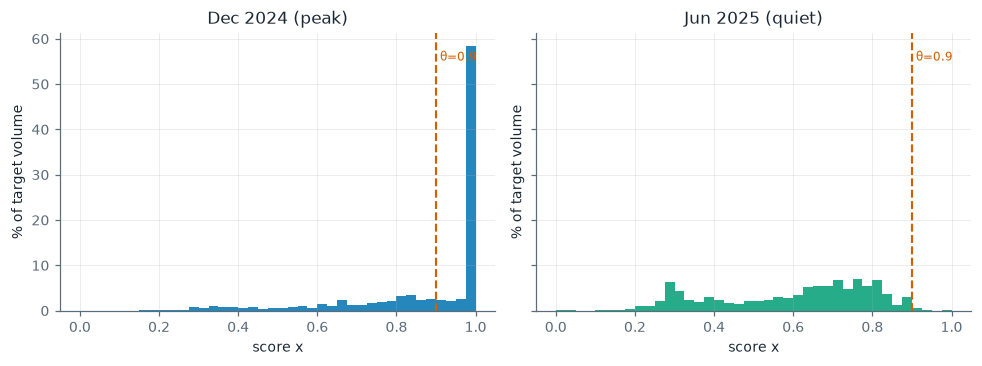

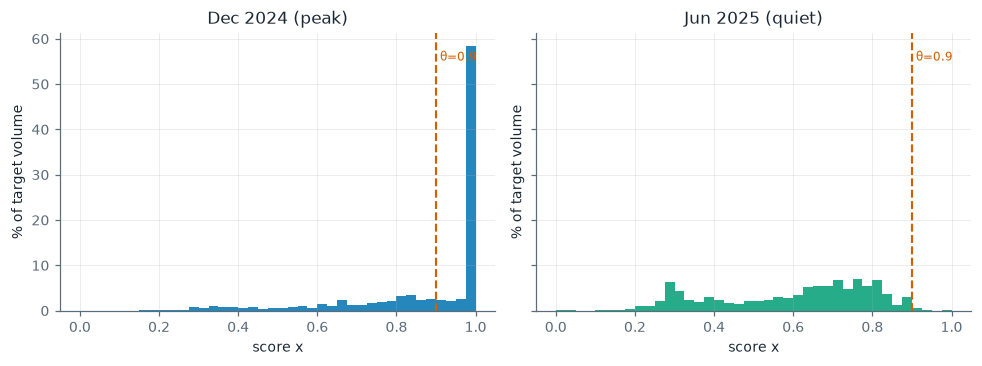

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, w in zip(axes, WIN):
    d = fl[w]
    wsum = d["target_vol"].sum()
    wts = 100 * d["target_vol"] / wsum if wsum > 0 else None
    ax.hist(d["x"], bins=bins, weights=wts, color=WIN[w]["color"], alpha=0.85)
    ax.axvline(THETA, color=C_ALG, ls="--", lw=1.4)
    ax.set(title=f"{WIN[w]['label']}", xlabel="score x", ylabel="% of target volume")
    ax.text(THETA, ax.get_ylim()[1] * 0.9, f" θ={THETA}", color=C_ALG, fontsize=8)
    record_stat(w, "pct_target_volume_score_ge_theta",
                100 * d.loc[d["x"] >= THETA, "target_vol"].sum() / wsum if wsum > 0 else 0.0)
save_fig(fig, "r2_01_score_dist")
fig

**อ่านผลจริง:** กราฟ ธ.ค. มีมวล volume สูงใกล้ score 1 ส่วน มิ.ย. กระจายกว้างในช่วงประมาณ 0.2–0.9 ไม่พบหลักฐานเพียงพอให้เรียกว่าทั้งสองช่วงมีสองกลุ่มแยกชัดเจน สัดส่วน volume ฝั่งกระเป๋าที่ score ≥ 0.9 เท่ากับ 65.49% และ 0.82% ซึ่งนับ trade endpoints จึงต่างจาก volume ที่ทั้งสองฝั่งติดธง

## 3. โปรไฟล์: กระเป๋าถูกติดธงเทรดต่างจากกระเป๋าทั่วไปไหม

เอาธงมา join กับ **top-partner share** (คำนวณจาก trades เหมือนรอบ 1): ถ้ากระเป๋าถูกติดธงมักวน volume
ไปที่คู่ค้าหนึ่งหรือสองราย ค่า top-1 / top-2 share จะสูงกว่ากลุ่มไม่ถูกติดธงชัดเจน

In [5]:
SQL_EDGES = """
    SELECT wallet, partner, sum(shares) AS v
    FROM (
        SELECT maker AS wallet, taker AS partner, shares FROM '{t}' WHERE in_target
        UNION ALL
        SELECT taker AS wallet, maker AS partner, shares FROM '{t}' WHERE in_target
    )
    GROUP BY 1, 2
"""
SQL_TOP2 = """
    WITH e AS ({edges}),
    r AS (SELECT wallet, partner, v,
                 row_number() OVER (PARTITION BY wallet ORDER BY v DESC) AS rk FROM e)
    SELECT wallet, count(*) AS degree, sum(v) AS vol,
           max(v) FILTER (rk = 1) / sum(v)  AS s1,
           sum(v) FILTER (rk <= 2) / sum(v) AS s12
    FROM r GROUP BY 1
"""
prof = {}
for w in WIN:
    t2 = q(SQL_TOP2.format(edges=SQL_EDGES.format(t=trades(w))))
    prof[w] = fl[w].merge(t2[["wallet", "s1", "s12", "degree"]], on="wallet", how="left")
prof["dec2024"].head()

,wallet,x,x0,flagged,target_vol,target_wash_vol,in_wash_trade,n_markets,n_counterparties,s1,s12,degree
0,0x9d021959a751356920af708d9ef22750b04fedbf,0.544912,0.544206,False,152.931242,0.0,False,3,6,0.346946,0.539407,6.0
1,0x9d02c4712e8036c87d3b0e0d513c60fbfda23cc3,0.869253,0.994708,False,63141.884894,0.0,False,8,67,0.221549,0.385816,67.0
2,0x9d04bf50ddab60069791c4ff6dcdbe9be25d8cde,0.496870,0.000000,False,1.068782,0.0,False,1,1,1.000000,1.000000,1.0
3,0x9d04e879a1e344d1272709a4dcfe128e38063441,0.183822,0.000000,False,18.460019,0.0,False,4,4,0.644894,0.885655,4.0
4,0x9d058ad2e7de9a055cf819a9a171ea1ccb4328d4,0.670539,0.629843,False,50.766665,0.0,False,1,1,1.000000,1.000000,1.0


In [6]:
# Volume-weighted group means (a wallet's influence scales with its volume).
def group_profile(d: pd.DataFrame) -> pd.DataFrame:
    sub = d[d["target_vol"] > 0].copy()
    out = {}
    for name, g in sub.groupby(sub["flagged"].map({True: "flagged", False: "unflagged"})):
        wv = g["target_vol"]
        out[name] = {
            "wallets": len(g),
            "top-1 partner share": np.average(g["s1"].fillna(0), weights=wv),
            "top-2 partner share": np.average(g["s12"].fillna(0), weights=wv),
            "distinct partners (median)": g["degree"].median(),
            "markets (median)": g["n_markets"].median(),
        }
    return pd.DataFrame(out).T

for w in WIN:
    gp = group_profile(prof[w])
    for grp in gp.index:
        record_stat(w, f"{grp}_top1_share", float(gp.loc[grp, "top-1 partner share"]))
        record_stat(w, f"{grp}_top2_share", float(gp.loc[grp, "top-2 partner share"]))
    print(f"\n{WIN[w]['label']}")
    print(gp.round(3))


Dec 2024 (peak)
           wallets  top-1 partner share  top-2 partner share  \
flagged    30535.0                0.474                0.648   
unflagged  73651.0                0.183                0.280   

           distinct partners (median)  markets (median)  
flagged                           6.0               3.0  
unflagged                         2.0               2.0  

Jun 2025 (quiet)
           wallets  top-1 partner share  top-2 partner share  \
flagged     6403.0                0.337                0.594   
unflagged  80727.0                0.187                0.289   

           distinct partners (median)  markets (median)  
flagged                           2.0               1.0  
unflagged                         2.0               1.0  


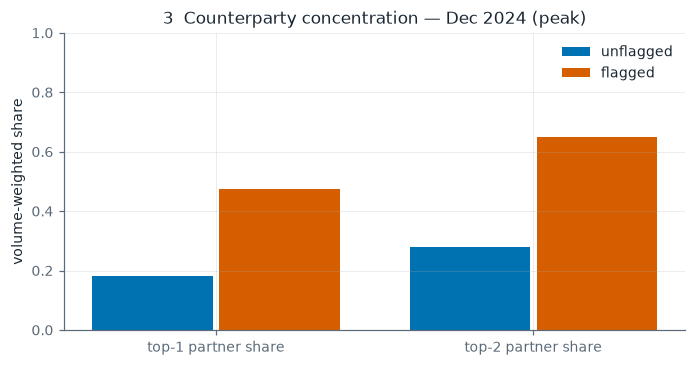

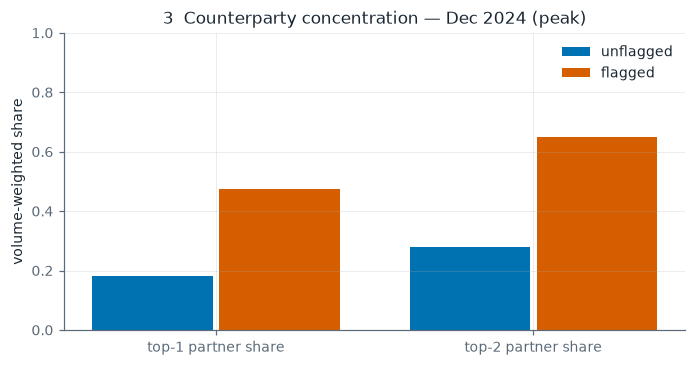

In [7]:
# Bar chart: flagged vs unflagged on the two concentration metrics (peak window).
w = "dec2024"
gp = group_profile(prof[w])
metrics = ["top-1 partner share", "top-2 partner share"]
xpos = np.arange(len(metrics))
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for j, grp in enumerate(["unflagged", "flagged"]):
    if grp in gp.index:
        ax.bar(xpos + (j - 0.5) * 0.4, gp.loc[grp, metrics].astype(float),
               width=0.38, color=GRP[grp], label=grp)
ax.set_xticks(xpos); ax.set_xticklabels(metrics)
ax.set(ylim=(0, 1), ylabel="volume-weighted share", title=f"3  Counterparty concentration — {WIN[w]['label']}")
ax.legend(frameon=False)
save_fig(fig, "r2_02_profile")
fig

**อ่านผลจริง:** ใน ธ.ค. กลุ่มติดธงมี top-1/top-2 partner share ถ่วงด้วย volume เท่ากับ 47.35%/64.81% เทียบกับ 18.30%/28.03% ในกลุ่มไม่ติดธง ส่วน มิ.ย. เท่ากับ 33.71%/59.44% เทียบกับ 18.72%/28.89% สะท้อนการกระจุกกับคู่เทรดสูงกว่า แต่ยังไม่ได้พิสูจน์โครงสร้างวงแหวนหรือการสมรู้ร่วมคิด

## 4. Volume ที่ถูกติดธงกระจุกที่ไหน: หมวดตลาด + ราคา

นิยาม trade ที่ติดธง = ทั้งสองกระเป๋า score ≥ θ ส่วน unflagged คือ trade ที่ไม่ผ่านเกณฑ์นี้ ไม่ใช่ข้อมูลที่ยืนยันแล้วว่าปลอด wash หมวดตลาดจัดด้วยคีย์เวิร์ดใน notebook นี้

In [8]:
SQL_CATEGORY = r"""
    WITH md AS (
        SELECT condition,
               lower(coalesce(any_value(marketName), '') || ' ' ||
                     coalesce(any_value(marketSlug), '')) AS txt
        FROM '{markets}' GROUP BY condition
    )
    SELECT condition AS market,
           CASE
             WHEN regexp_matches(txt, '\b(bitcoin|btc|eth|ethereum|solana|sol|xrp|crypto|memecoin|token|airdrop|binance|coinbase|usdc|usdt|pepe)\b') THEN 'Crypto'
             WHEN regexp_matches(txt, '\b(nba|nfl|nhl|mlb|ncaa|ufc|mma|super bowl|stanley cup|premier league|champions league|uefa|fifa|f1|grand prix|playoffs?|finals?|championship|tennis|golf|boxing|fight|vs\.?|world series|olympics?)\b') THEN 'Sports'
             WHEN regexp_matches(txt, '\b(fed|interest rates?|inflation|cpi|gdp|recession|unemployment|tariffs?|s&p|nasdaq|stocks?|treasury|gold|oil)\b') THEN 'Economy'
             WHEN regexp_matches(txt, '\b(trump|biden|harris|election|elected|president|senate|house|governor|primary|democrat\w*|republican\w*|votes?|inaugurated|ceasefire|war|nato|ukraine|russia|israel|gaza|iran)\b') THEN 'Politics'
             ELSE 'Other'
           END AS category
    FROM md
""".format(markets=MARKETS)
CATS = ["Sports", "Politics", "Crypto", "Economy", "Other"]

SQL_SPLIT = """
    WITH t AS (SELECT * FROM '{t}' WHERE in_target),
    f AS (SELECT wallet, flagged FROM '{f}'),
    cat AS ({cat}),
    tt AS (
        SELECT t.shares, t.usdc, cat.category,
               (fa.flagged AND fb.flagged) AS wash
        FROM t JOIN f fa ON fa.wallet = t.maker
               JOIN f fb ON fb.wallet = t.taker
               LEFT JOIN cat ON cat.market = t.market
    )
    SELECT coalesce(category, 'Other') AS category,
           sum(shares) FILTER (wash)     AS wash_vol,
           sum(shares) FILTER (NOT wash) AS clean_vol,
           sum(shares) FILTER (wash AND usdc / shares < 0.02) AS wash_vol_lowprice,
           sum(shares) FILTER (wash)     AS wash_vol2
    FROM tt GROUP BY 1
"""
split = {w: q(SQL_SPLIT.format(t=trades(w), f=flags(w), cat=SQL_CATEGORY)) for w in WIN}
split["dec2024"]

,category,wash_vol,clean_vol,wash_vol_lowprice,wash_vol2
0,Economy,2.079441e+06,7.936726e+06,5.821176e+05,2.079441e+06
1,Politics,9.449409e+07,7.765547e+07,5.524512e+07,9.449409e+07
2,Sports,2.920294e+08,8.678717e+07,2.421328e+08,2.920294e+08
3,Crypto,1.676090e+06,6.020866e+07,1.359669e+04,1.676090e+06
4,Other,3.809190e+07,3.192323e+07,3.330334e+07,3.809190e+07


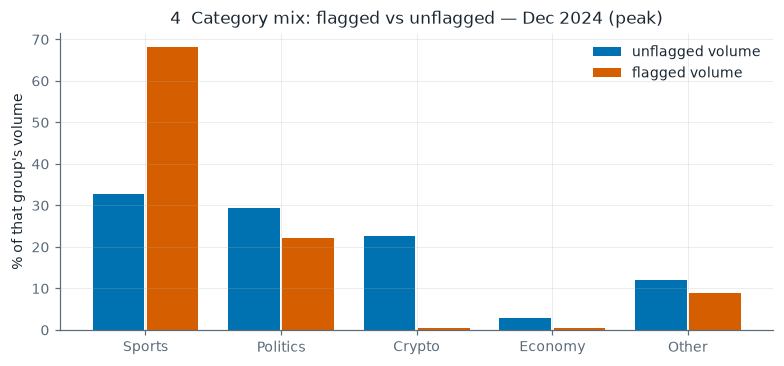

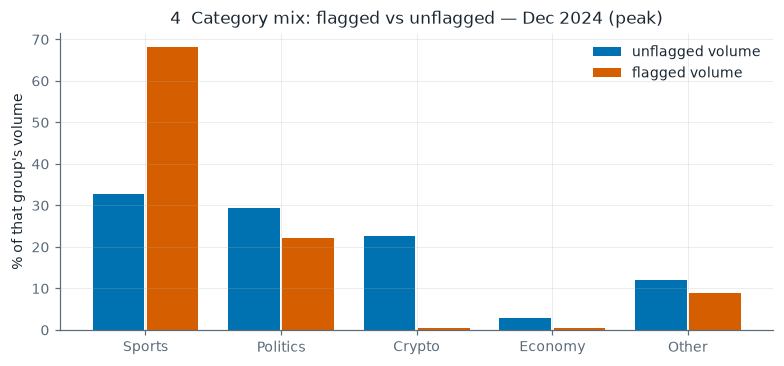

In [9]:
# Category mix of wash vs clean volume (peak window) + low-price share of wash volume.
w = "dec2024"
s = split[w].set_index("category").reindex(CATS).fillna(0.0)
wash_mix = 100 * s["wash_vol"] / s["wash_vol"].sum() if s["wash_vol"].sum() > 0 else s["wash_vol"] * 0
clean_mix = 100 * s["clean_vol"] / s["clean_vol"].sum() if s["clean_vol"].sum() > 0 else s["clean_vol"] * 0

fig, ax = plt.subplots(figsize=(7.2, 3.4))
xpos = np.arange(len(CATS))
ax.bar(xpos - 0.2, clean_mix, width=0.38, color=C_DATA, label="unflagged volume")
ax.bar(xpos + 0.2, wash_mix, width=0.38, color=C_ALG, label="flagged volume")
ax.set_xticks(xpos); ax.set_xticklabels(CATS)
ax.set(ylabel="% of that group's volume", title=f"4  Category mix: flagged vs unflagged — {WIN[w]['label']}")
ax.legend(frameon=False)
save_fig(fig, "r2_03_category_price")

for w in WIN:
    s = split[w]
    wv = s["wash_vol"].sum()
    record_stat(w, "pct_wash_volume_sports",
                100 * s.loc[s["category"] == "Sports", "wash_vol"].sum() / wv if wv > 0 else 0.0)
    record_stat(w, "pct_wash_volume_price_lt_0.02",
                100 * s["wash_vol_lowprice"].sum() / wv if wv > 0 else 0.0)
fig

**อ่านผลจริง:** ใน ธ.ค. volume ที่ถูกติดธง 68.17% อยู่ในหมวด Sports และ 77.33% มีราคา < 0.02 USDC ส่วน มิ.ย. เท่ากับ 19.29% และ 62.61% ตามลำดับ หมวดเป็น keyword heuristic ซึ่งกฎบางส่วนต่างจากรอบแรก จึงไม่ควรนำสัดส่วนหมวดข้าม notebook มาเทียบโดยไม่จัดหมวดใหม่ให้ตรงกัน

## 5. การเทรดระหว่างกระเป๋าที่ถูกติดธง

วัดต่อกระเป๋าที่ถูกติดธงว่ามีสัดส่วน volume เทรดกับกระเป๋าที่ถูกติดธงด้วยกันเท่าใด ค่านี้เป็นคำอธิบายผล detector และสัมพันธ์กับการแพร่ score ผ่านคู่เทรด ไม่ใช่การยืนยัน wash หรือ chip dumping อย่างอิสระ

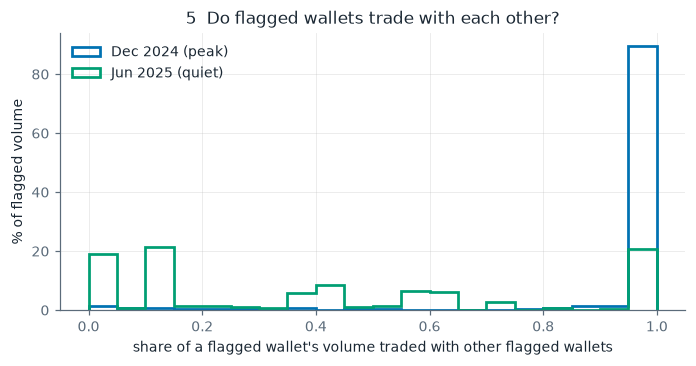

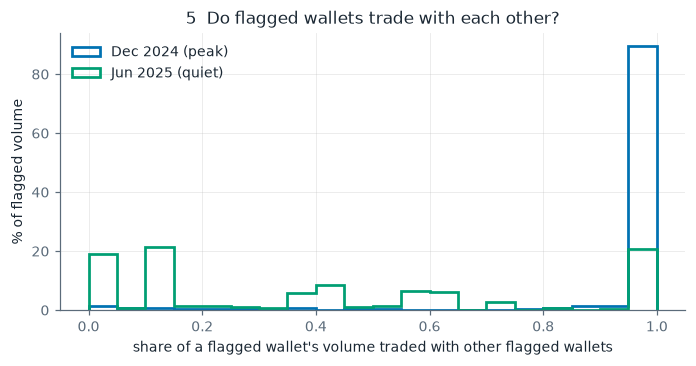

In [10]:
SQL_ASSORT = """
    WITH e AS (
        SELECT maker AS wallet, taker AS partner, shares FROM '{t}' WHERE in_target
        UNION ALL
        SELECT taker AS wallet, maker AS partner, shares FROM '{t}' WHERE in_target
    ),
    f AS (SELECT wallet, flagged FROM '{f}')
    SELECT e.wallet,
           sum(e.shares)                     AS vol,
           sum(e.shares) FILTER (pf.flagged) AS vol_with_flagged
    FROM e JOIN f ff ON ff.wallet = e.wallet
           JOIN f pf ON pf.wallet = e.partner
    WHERE ff.flagged
    GROUP BY 1
"""
fig, ax = plt.subplots(figsize=(6.4, 3.4))
bins = np.linspace(0, 1, 21)
for w in WIN:
    a = q(SQL_ASSORT.format(t=trades(w), f=flags(w)))
    if len(a) == 0:
        continue
    frac = (a["vol_with_flagged"] / a["vol"]).fillna(0)
    ax.hist(frac, bins=bins, weights=100 * a["vol"] / a["vol"].sum(),
            histtype="step", lw=1.8, color=WIN[w]["color"], label=WIN[w]["label"])
    record_stat(w, "median_flagged_vol_share_with_flagged", float(frac.median()))
    record_stat(w, "pct_flagged_volume_mostly_with_flagged",
                100 * a.loc[frac >= 0.9, "vol"].sum() / a["vol"].sum())
ax.set(xlabel="share of a flagged wallet's volume traded with other flagged wallets",
       ylabel="% of flagged volume", title="5  Do flagged wallets trade with each other?")
ax.legend(frameon=False)
save_fig(fig, "r2_04_assortativity")
fig

**อ่านผลจริง:** ใน ธ.ค. 90.98% ของ volume ฝั่งกระเป๋าที่ติดธงมาจากกระเป๋าที่ส่ง volume ≥ 90% ให้คู่เทรดที่ติดธงด้วยกัน เทียบกับ 21.11% ใน มิ.ย. แต่ median ต่อกระเป๋าอยู่ที่ 51.91% และ 41.18% แสดงว่าภาพถ่วง volume ถูกขับโดยกระเป๋าขนาดใหญ่ ไม่ได้หมายความว่ากระเป๋าส่วนใหญ่เป็นวงปิด และยังพิสูจน์ chip dumping ไม่ได้

## 6. สรุปผลบนข้อมูลจริง (23 ต.ค. 2026)

- ธ.ค. มี volume ที่ทั้งสองฝั่งติดธง 61.82% เทียบกับ 0.35% ใน มิ.ย.
- กระเป๋าที่ติดธงกระจุกกับคู่เทรดมากกว่า โดยเฉพาะเมื่อถ่วงด้วย volume
- ใน ธ.ค. volume ที่ติดธงส่วนใหญ่อยู่ในหมวดกีฬาและราคาต่ำกว่า 0.02 USDC
- พฤติกรรมเทรดกับกระเป๋าที่ติดธงด้วยกันเด่นในกลุ่ม volume สูง แต่ไม่ยืนยันวงแหวนหรือ chip dumping
- ผลนี้ครอบคลุมสอง baseline weeks เท่านั้น การวิเคราะห์ 18 สัปดาห์ยังเป็นงานถัดไป
- Synthetic injection และ Trump θ-sensitivity ดูผลและข้อจำกัดใน `evaluation_findings.md`

In [11]:
(HERE / "eda_round2_stats.json").write_text(json.dumps(STATS, indent=2, default=str))
print(f"saved {sum(len(v) for v in STATS.values())} numbers -> eda_round2_stats.json")
print("figures:", sorted(p.name for p in FIG.glob("r2_*.png")))

saved 26 numbers -> eda_round2_stats.json
figures: ['r2_01_score_dist.png', 'r2_02_profile.png', 'r2_03_category_price.png', 'r2_04_assortativity.png']
